# School-site suitability in TA Chimaliro, Thyolo, Malawi
**Purpose.** Identify land within TA Chimaliro that is at least 2,000 m from mapped existing primary schools, no more than 500 m from mapped main roads, and outside mapped protected areas.

> **Important:** Run all cells from top to bottom with an internet connection. This notebook retrieves current public data; results depend on the availability and completeness of the boundary, OpenStreetMap and protected-area sources. Do not treat the output as a cadastral or engineering approval.

## 1. Data Sources and Metadata

- **Chimaliro boundary:** The original Chimaliro boundary dataset defines the spatial extent of the study area. It serves as the reference boundary for clipping and extracting the primary schools, protected areas, rivers, and roads datasets.

- **Primary schools:** The original primary schools dataset provides the locations of primary educational facilities within the Chimaliro study area. It is used to analyze the spatial distribution and accessibility of primary schools.

- **Protected areas:** The original protected areas dataset represents designated or mapped conservation areas within the study area. It is used to assess the spatial distribution of protected areas and their relationship with other environmental features.

- **Rivers:** The original rivers dataset represents the river network within the Chimaliro study area. It supports the analysis of drainage patterns and the spatial relationships between rivers, roads, schools, and protected areas.

- **Roads:** The original roads dataset represents the road network within the Chimaliro study area. It is used for road-network mapping and accessibility analysis, including assessing connections to primary schools and other important locations.

- **Data formats and metadata:** The original datasets are used as the primary data sources. Their file formats, coordinate reference systems (CRSs), acquisition dates, source information, and attribute fields are documented where available. Datasets are converted to compatible GIS formats where necessary.

- **Analysis CRS:** EPSG:32736 (WGS 84 / UTM zone 36S) is used as the projected coordinate reference system for spatial analysis, provided that it is appropriate for the Chimaliro study area. All distance and area calculations are performed after reprojection to the selected CRS.

- **Data preparation and quality control:** All datasets are checked for missing attributes, invalid geometries, duplicate features, and spatial alignment. The primary schools, protected areas, rivers, and roads datasets are clipped to the Chimaliro boundary where appropriate. Original datasets are preserved, and processed outputs are documented separately.

In [10]:
from pathlib import Path
from datetime import datetime, timezone
import json, time, warnings
import requests
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import folium
from shapely.geometry import shape, box
from shapely.ops import unary_union

# Project directory
ROOT = Path(r"D:\chimaliro-school-site-accessibility")

# Original and processed data directories
DATA = ROOT / "data"
PROC = DATA / "processed_data"
RAW = DATA / "raw_data"
OUT = ROOT / "outputs"

# Create folders if they do not exist
for folder in (RAW, PROC, OUT):
    folder.mkdir(parents=True, exist_ok=True)

# Coordinate reference system for spatial analysis
CRS_METRIC = "EPSG:32736"

# Record analysis timestamp
accessed = datetime.now(timezone.utc).isoformat()

print("Project root:", ROOT)
print("Data directory:", DATA)
print("Processed datasets:", PROC)
print("Raw data directory:", RAW)
print("Output directory:", OUT)
print("Run timestamp (UTC):", accessed)
print("Analysis CRS:", CRS_METRIC)

# List files in your processed_data folder
print("\nFiles in processed_data:")
for file in sorted(PROC.iterdir()):
    print(file.name)

Project root: D:\chimaliro-school-site-accessibility
Data directory: D:\chimaliro-school-site-accessibility\data
Processed datasets: D:\chimaliro-school-site-accessibility\data\processed_data
Raw data directory: D:\chimaliro-school-site-accessibility\data\raw_data
Output directory: D:\chimaliro-school-site-accessibility\outputs
Run timestamp (UTC): 2026-10-24T11:28:31.135102+00:00
Analysis CRS: EPSG:32736

Files in processed_data:


## 2. Chimaliro boundary
geoBoundaries provides open administrative boundary datasets. The available administrative levels may not represent Traditional Authorities exactly.

In [11]:
from pathlib import Path

# Path to your original datasets
RAW = Path(r"D:\chimaliro-school-site-accessibility\data\raw_data")

# List all files in raw_data
print("Available original datasets:\n")

for file in sorted(RAW.iterdir()):
    if file.is_file():
        print(file.name)

Available original datasets:

Boundary.cpg
Boundary.dbf
Boundary.prj
Boundary.sbn
Boundary.sbx
Boundary.shp
Boundary.shp.xml
Boundary.shx
primary schools.cpg
primary schools.dbf
primary schools.prj
primary schools.sbn
primary schools.sbx
primary schools.shp
primary schools.shp.xml
primary schools.shx
protected area.cpg
protected area.dbf
protected area.prj
protected area.sbn
protected area.sbx
protected area.shp
protected area.shp.xml
protected area.shx
rivers.cpg
rivers.dbf
rivers.prj
rivers.sbn
rivers.sbx
rivers.shp
rivers.shp.xml
rivers.shx
roads.cpg
roads.dbf
roads.prj
roads.sbn
roads.sbx
roads.shp
roads.shp.xml
roads.shx


## **Checking CRS For all datasets**

In [12]:
from pathlib import Path
import geopandas as gpd

# Project directories
ROOT = Path(r"D:\chimaliro-school-site-accessibility")
RAW = ROOT / "data" / "raw_data"
PROC = ROOT / "data" / "processed_data"
OUT = ROOT / "outputs"

# Create output directories if needed
PROC.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# Load original shapefiles
boundary = gpd.read_file(RAW / "Boundary.shp")
schools = gpd.read_file(RAW / "primary schools.shp")
protected_areas = gpd.read_file(RAW / "protected area.shp")
rivers = gpd.read_file(RAW / "rivers.shp")
roads = gpd.read_file(RAW / "roads.shp")

# Store datasets in a dictionary for convenient processing
datasets = {
    "Boundary": boundary,
    "Primary Schools": schools,
    "Protected Areas": protected_areas,
    "Rivers": rivers,
    "Roads": roads,
}

# Display dataset information
for name, gdf in datasets.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Features:", len(gdf))
    print("CRS:", gdf.crs)
    print("Geometry types:", gdf.geom_type.value_counts().to_dict())
    print("Columns:", gdf.columns.tolist())


Boundary
----------------------------------------
Features: 1
CRS: EPSG:4326
Geometry types: {'Polygon': 1}
Columns: ['NAME_1', 'Region', 'Regionn', 'TOTAL', 'C15', 'C17', 'C19', 'C21', 'C23', 'RFF', 'Field', 'ZONES', 'C13_TOTAL', 'C15_TOTAL', 'C17_TOTAL', 'C19_TOTAL', 'C21_TOTAL', 'C23_TOTAL', 'C5_TOTAL', 'C7_TOTAL', 'C9_TOTAL', 'C1_TOTAL', 'C223_TOTAL', 'Target', 'geometry']

Primary Schools
----------------------------------------
Features: 139
CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["GCS_unnamed ellipse",DATUM["unknown",SPHEROID["Unknown",6378249.145,293.466307699991]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometry types: {'Point': 139}
Columns: ['X', 'Y', 'Distri

# **Reprojecting all datasets**

In [15]:
from pathlib import Path
import geopandas as gpd

ROOT = Path(r"D:\chimaliro-school-site-accessibility")
RAW = ROOT / "data" / "raw_data"
PROC = ROOT / "data" / "processed_data"
PROC.mkdir(parents=True, exist_ok=True)

TARGET_CRS = "EPSG:32736"

# Load original datasets
boundary = gpd.read_file(RAW / "Boundary.shp")
schools = gpd.read_file(RAW / "primary schools.shp")
protected_areas = gpd.read_file(RAW / "protected area.shp")
rivers = gpd.read_file(RAW / "rivers.shp")
roads = gpd.read_file(RAW / "roads.shp")

# Reproject the boundary from WGS 84 geographic coordinates
boundary_utm = boundary.to_crs(TARGET_CRS)

# Check source CRS of the remaining layers
for name, gdf in {
    "Primary schools": schools,
    "Protected areas": protected_areas,
    "Rivers": rivers,
    "Roads": roads,
}.items():
    print(f"{name}:")
    print("  Source CRS:", gdf.crs)
    print("  Recognized EPSG:", gdf.crs.to_epsg())
    print("  Bounds:", gdf.total_bounds)

print("\nBoundary CRS:", boundary_utm.crs)
print("Boundary bounds in metres:", boundary_utm.total_bounds)

Primary schools:
  Source CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["GCS_unnamed ellipse",DATUM["unknown",SPHEROID["Unknown",6378249.145,293.466307699991]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
  Recognized EPSG: 20936
  Bounds: [ 577509.11069617 8505694.54932042  619883.29445983 8556672.7490338 ]
Protected areas:
  Source CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["GCS_unnamed ellipse",DATUM["unknown",SPHEROID["Unknown",6378249.145,293.466307699991]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easti

## Exporting collected data CRS 

In [18]:
from pathlib import Path
import geopandas as gpd

# Project folders
ROOT = Path(r"D:\chimaliro-school-site-accessibility")
RAW = ROOT / "data" / "raw_data"
PROC = ROOT / "data" / "processed_data"
PROC.mkdir(parents=True, exist_ok=True)

# Target CRS
TARGET_CRS = "EPSG:32736"  # WGS 84 / UTM Zone 36S

# Load original datasets
boundary = gpd.read_file(RAW / "Boundary.shp")
schools = gpd.read_file(RAW / "primary schools.shp")
protected_areas = gpd.read_file(RAW / "protected area.shp")
rivers = gpd.read_file(RAW / "rivers.shp")
roads = gpd.read_file(RAW / "roads.shp")

# Reproject boundary from EPSG:4326
boundary_utm = boundary.to_crs(TARGET_CRS)

# Confirm the legacy CRS before proceeding
SOURCE_CRS = "EPSG:21036"

for name, gdf in {
    "Schools": schools,
    "Protected areas": protected_areas,
    "Rivers": rivers,
    "Roads": roads,
}.items():
    print(name, "source CRS:", gdf.crs)

# Assign the verified source CRS and reproject
# ONLY do this if EPSG:21036 is confirmed for these layers.
schools_utm = schools.set_crs(SOURCE_CRS, allow_override=True).to_crs(TARGET_CRS)
protected_areas_utm = protected_areas.set_crs(SOURCE_CRS, allow_override=True).to_crs(TARGET_CRS)
rivers_utm = rivers.set_crs(SOURCE_CRS, allow_override=True).to_crs(TARGET_CRS)
roads_utm = roads.set_crs(SOURCE_CRS, allow_override=True).to_crs(TARGET_CRS)

# Save all five datasets
reprojected = {
    "Boundary": boundary_utm,
    "primary_schools": schools_utm,
    "protected_areas": protected_areas_utm,
    "rivers": rivers_utm,
    "roads": roads_utm,
}

for name, gdf in reprojected.items():
    output_file = PROC / f"{name}_UTM36S.shp"
    gdf.to_file(output_file, driver="ESRI Shapefile", index=False)
    print(f"Saved: {output_file.name} | CRS: {gdf.crs}")

Schools source CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["GCS_unnamed ellipse",DATUM["unknown",SPHEROID["Unknown",6378249.145,293.466307699991]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Protected areas source CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["GCS_unnamed ellipse",DATUM["unknown",SPHEROID["Unknown",6378249.145,293.466307699991]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["No

## VERIFYING DATA

In [19]:
from pathlib import Path
import geopandas as gpd

PROC = Path(r"D:\chimaliro-school-site-accessibility\data\processed_data")

files = {
    "Boundary": "Boundary_UTM36S.shp",
    "Primary Schools": "primary_schools_UTM36S.shp",
    "Protected Areas": "protected_areas_UTM36S.shp",
    "Rivers": "rivers_UTM36S.shp",
    "Roads": "roads_UTM36S.shp",
}

for name, filename in files.items():
    path = PROC / filename
    gdf = gpd.read_file(path)

    print(f"\n{name}")
    print("Features:", len(gdf))
    print("CRS:", gdf.crs)
    print("Bounds:", gdf.total_bounds)

    assert gdf.crs.to_epsg() == 32736, f"{name} has the wrong CRS!"

print("\nAll five datasets passed the CRS verification.")


Boundary
Features: 1
CRS: EPSG:32736
Bounds: [ 575581.29812566 8503456.09868     621991.88199154 8561247.08904783]

Primary Schools
Features: 139
CRS: EPSG:32736
Bounds: [ 577590.83311742 8505393.82905474  619964.80791482 8556371.80045569]

Protected Areas
Features: 2
CRS: EPSG:32736
Bounds: [ 598718.3322143  8518998.21799759  620071.14750671 8555914.98523623]

Rivers
Features: 51
CRS: EPSG:32736
Bounds: [ 575804.60660018 8506056.67175001  620704.34073191 8560861.03042063]

Roads
Features: 1977
CRS: EPSG:32736
Bounds: [ 576304.22927105 8503386.3714139   621904.77922787 8560520.03159962]

All five datasets passed the CRS verification.


## Visualizing all datasets

Boundary: 1 features | CRS: EPSG:32736
Schools: 139 features | CRS: EPSG:32736
Protected areas: 2 features | CRS: EPSG:32736
Rivers: 51 features | CRS: EPSG:32736
Roads: 1977 features | CRS: EPSG:32736


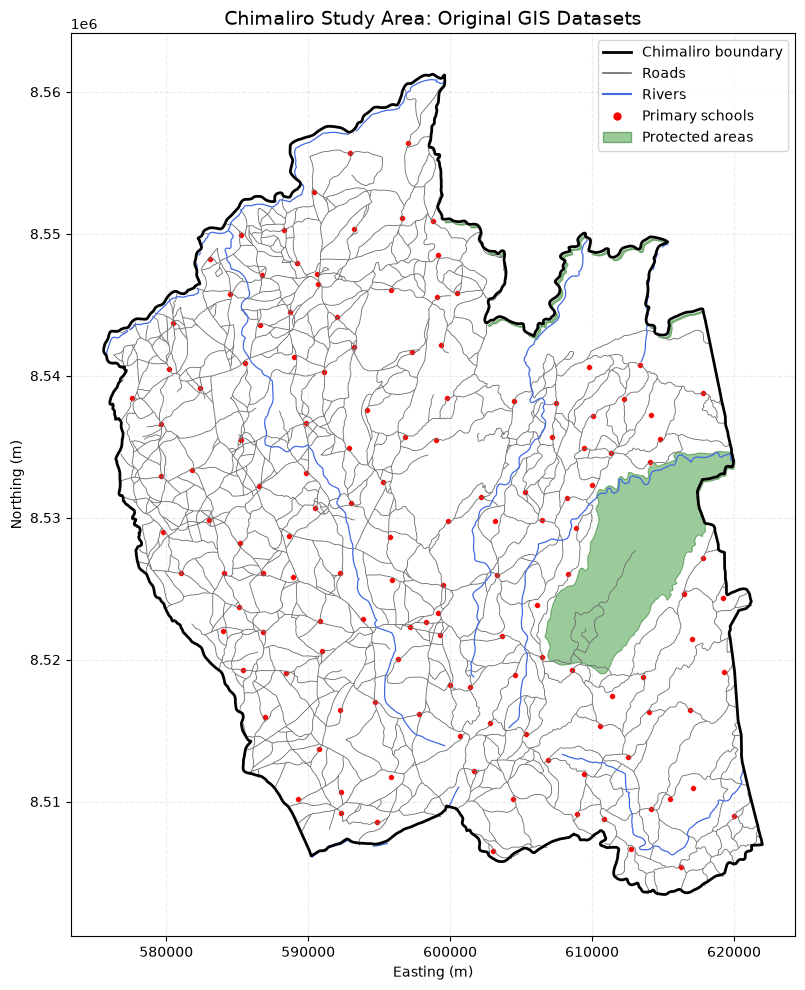

Map saved to: D:\chimaliro-school-site-accessibility\outputs\chimaliro_all_datasets.png


In [21]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Project directory
PROC = Path(
    r"D:\chimaliro-school-site-accessibility\data\processed_data"
)

# Load reprojected datasets
boundary = gpd.read_file(PROC / "Boundary_UTM36S.shp")
schools = gpd.read_file(PROC / "primary_schools_UTM36S.shp")
protected_areas = gpd.read_file(PROC / "protected_areas_UTM36S.shp")
rivers = gpd.read_file(PROC / "rivers_UTM36S.shp")
roads = gpd.read_file(PROC / "roads_UTM36S.shp")

# Ensure every layer has the expected CRS
for name, gdf in {
    "Boundary": boundary,
    "Schools": schools,
    "Protected areas": protected_areas,
    "Rivers": rivers,
    "Roads": roads,
}.items():
    print(f"{name}: {len(gdf)} features | CRS: {gdf.crs}")

# Plot datasets
fig, ax = plt.subplots(figsize=(12, 10))

protected_areas.plot(
    ax=ax, color="forestgreen", alpha=0.45,
    edgecolor="darkgreen", linewidth=0.8
)

roads.plot(
    ax=ax, color="dimgray", linewidth=0.6
)

rivers.plot(
    ax=ax, color="royalblue", linewidth=0.9
)

schools.plot(
    ax=ax, color="red", markersize=18,
    edgecolor="white", linewidth=0.4
)

boundary.boundary.plot(
    ax=ax, color="black", linewidth=2
)

# Legend
legend_items = [
    Line2D([0], [0], color="black", linewidth=2,
           label="Chimaliro boundary"),
    Line2D([0], [0], color="dimgray", linewidth=1.2,
           label="Roads"),
    Line2D([0], [0], color="royalblue", linewidth=1.5,
           label="Rivers"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="red", markersize=7,
           label="Primary schools"),
    Patch(facecolor="forestgreen", alpha=0.45,
          edgecolor="darkgreen", label="Protected areas"),
]

ax.legend(handles=legend_items, loc="best", frameon=True)
ax.set_title(
    "Chimaliro Study Area: Original GIS Datasets",
    fontsize=14
)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.25)

plt.tight_layout()

# Save the map
OUT = Path(r"D:\chimaliro-school-site-accessibility\outputs")
OUT.mkdir(parents=True, exist_ok=True)

plt.savefig(
    OUT / "chimaliro_all_datasets.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Map saved to:", OUT / "chimaliro_all_datasets.png")

## 5. Apply the criteria using metric buffers and overlays
The qualifying land is the TA polygon intersected with (a) land outside a 2 km buffer around existing primary schools and (b) land within 500 m of main roads. Protected areas are then subtracted. Distances are Euclidean planimetric distances, not network travel distances.


ROAD_CLASS values:
ROAD_CLASS
Other Roads       1651
District Road      114
Tertiary Road      102
Main Road           91
Secondary Road      19

MROAD_TYPE values:
MROAD_TYPE
Unclassified    1636
M7                49
T340              48
M18               42
T350              32
D113              21
T341              21
S116              19
D105              19
D101              16
unclassified      15
D102              14
D103              12
D98                8
D106               7
D107               6
D99                5
D112               3
D111               2
D109               1
T104               1

Main-road features selected: 110

Suitability analysis complete.
Suitable land area: 2,094.96 hectares
Saved output: D:\chimaliro-school-site-accessibility\outputs\chimaliro_suitability.gpkg
GeoPackage layers: ['school_exclusion_2km', 'main_road_access_500m', 'candidate_before_protection', 'suitable_land']


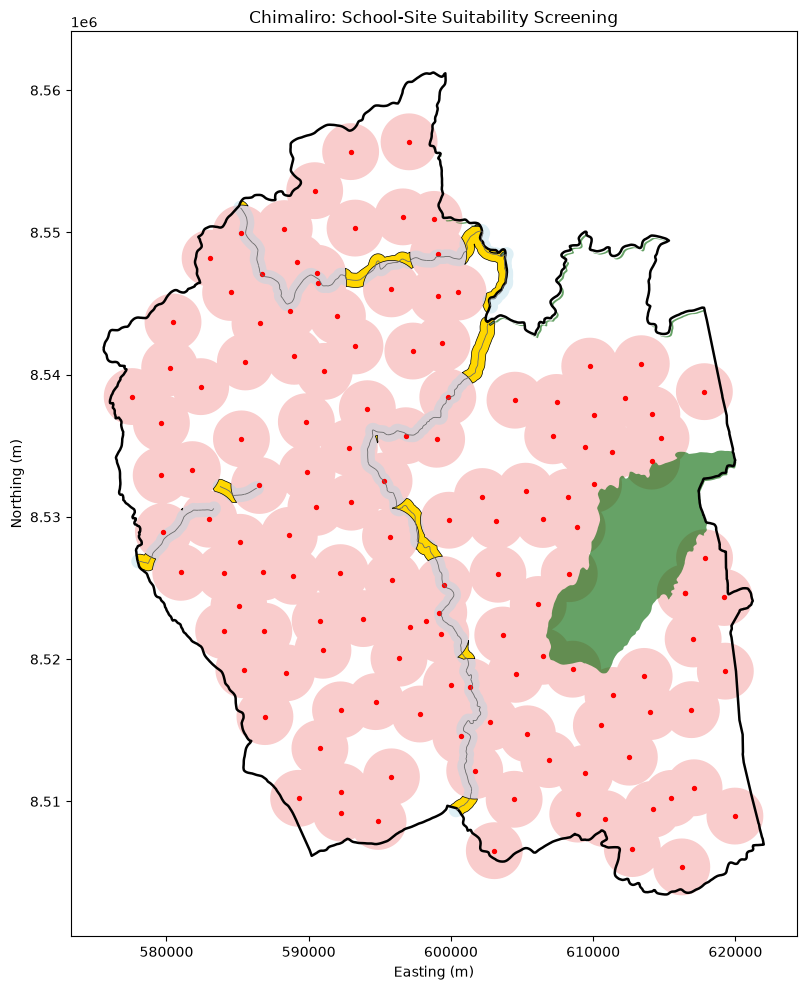

In [23]:

from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from shapely.ops import unary_union

# 1. Project paths and analysis parameters

ROOT = Path(r"D:\chimaliro-school-site-accessibility")
PROC = ROOT / "data" / "processed_data"
OUT = ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

CRS = "EPSG:32736"  # WGS 84 / UTM Zone 36S
SCHOOL_BUFFER_M = 2000
ROAD_BUFFER_M = 500


# 2. Load the reprojected datasets

boundary = gpd.read_file(PROC / "Boundary_UTM36S.shp")
schools = gpd.read_file(PROC / "primary_schools_UTM36S.shp")
protected = gpd.read_file(PROC / "protected_areas_UTM36S.shp")
roads = gpd.read_file(PROC / "roads_UTM36S.shp")

layers = {
    "Boundary": boundary,
    "Schools": schools,
    "Protected areas": protected,
    "Roads": roads,
}

# Verify CRS before distance operations
for name, gdf in layers.items():
    if gdf.crs is None or gdf.crs.to_epsg() != 32736:
        raise ValueError(
            f"{name} must have a verified EPSG:32736 CRS. "
            f"Current CRS: {gdf.crs}"
        )
    if gdf.empty:
        raise ValueError(f"{name} contains no features.")


# 3. Inspect road classifications

for field in ["ROAD_CLASS", "MROAD_TYPE"]:
    if field in roads.columns:
        print(f"\n{field} values:")
        print(roads[field].value_counts(dropna=False).to_string())

# Identify main roads using descriptive class names.
# Review the values above and adjust if your dataset
# uses numeric or abbreviated road-class codes.
main_road_mask = pd.Series(False, index=roads.index)

for field in ["ROAD_CLASS", "MROAD_TYPE"]:
    if field in roads.columns:
        main_road_mask |= roads[field].astype(str).str.contains(
            r"primary|secondary|trunk|main|major",
            case=False,
            na=False,
            regex=True,
        )

main_roads = roads.loc[main_road_mask].copy()

if main_roads.empty:
    raise ValueError(
        "No main roads identified from the class names. "
        "Inspect the printed road-class values and set "
        "main_road_mask to match the actual main-road classes. "
        "Do not automatically use every road."
    )

print("\nMain-road features selected:", len(main_roads))


# 4. Prepare valid geometries and study boundary

def clean_geometries(gdf):
    gdf = gdf.loc[
        gdf.geometry.notna() & ~gdf.geometry.is_empty
    ].copy()
    gdf.geometry = gdf.geometry.make_valid()
    return gdf

boundary = clean_geometries(boundary)
schools = clean_geometries(schools)
protected = clean_geometries(protected)
main_roads = clean_geometries(main_roads)

study_area = unary_union(boundary.geometry)
school_points = unary_union(schools.geometry)
road_network = unary_union(main_roads.geometry)
protected_union = unary_union(protected.geometry)


# 5. Build metric buffers

school_exclusion = school_points.buffer(SCHOOL_BUFFER_M)
road_access_zone = road_network.buffer(ROAD_BUFFER_M)

# Land inside the boundary but outside school buffers
outside_school_buffers = study_area.difference(
    school_exclusion
)

# Retain only land within 500 m of selected main roads
candidate_land = outside_school_buffers.intersection(
    road_access_zone
)

# Remove protected areas
suitable_land = candidate_land.difference(
    protected_union
)


# 6. Save the analysis outputs

results = {
    "school_exclusion_2km": school_exclusion,
    "main_road_access_500m": road_access_zone,
    "candidate_before_protection": candidate_land,
    "suitable_land": suitable_land,
}

output_file = OUT / "chimaliro_suitability.gpkg"

# Remove an existing output to avoid layer conflicts
if output_file.exists():
    output_file.unlink()

for layer_name, geom in results.items():
    if geom.is_empty:
        print(f"{layer_name}: no area remaining")
        continue

    result_gdf = gpd.GeoDataFrame(
        {"criterion": [layer_name]},
        geometry=[geom],
        crs=CRS,
    )
    result_gdf.to_file(
        output_file,
        layer=layer_name,
        driver="GPKG",
        mode="w" if layer_name == "school_exclusion_2km" else "a",
    )

# Calculate area in hectares
suitable_area_ha = (
    suitable_land.area / 10_000
    if suitable_land.geom_type == "Polygon"
    else sum(
        part.area for part in getattr(
            suitable_land, "geoms", []
        ) if part.geom_type == "Polygon"
    ) / 10_000
)

print("\nSuitability analysis complete.")
print(f"Suitable land area: {suitable_area_ha:,.2f} hectares")
print("Saved output:", output_file)
print("GeoPackage layers:", list(results.keys()))


# 7. Visualize the result

fig, ax = plt.subplots(figsize=(12, 10))

gpd.GeoSeries([study_area], crs=CRS).boundary.plot(
    ax=ax, color="black", linewidth=1.8
)
gpd.GeoSeries([school_exclusion], crs=CRS).plot(
    ax=ax, color="lightcoral", alpha=0.4
)
gpd.GeoSeries([road_access_zone], crs=CRS).plot(
    ax=ax, color="lightblue", alpha=0.4
)
gpd.GeoSeries([protected_union], crs=CRS).plot(
    ax=ax, color="darkgreen", alpha=0.6
)

if not suitable_land.is_empty:
    gpd.GeoSeries([suitable_land], crs=CRS).plot(
        ax=ax, color="gold", edgecolor="black",
        linewidth=0.5
    )

schools.plot(ax=ax, color="red", markersize=8)
main_roads.plot(ax=ax, color="dimgray", linewidth=0.6)

ax.set_title("Chimaliro: School-Site Suitability Screening")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()

plt.savefig(
    OUT / "chimaliro_suitability_map.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 6. Create a static map
The map is plotted in the projected CRS. The graphic includes a title, legend, scale bar, north arrow and source notes.

In [24]:
%pip install matplotlib-scalebar

Note: you may need to restart the kernel to use updated packages.


Boundary: 1 features | CRS: EPSG:32736
Primary schools: 139 features | CRS: EPSG:32736
Protected areas: 2 features | CRS: EPSG:32736
Roads: 1977 features | CRS: EPSG:32736
Rivers: 51 features | CRS: EPSG:32736
Suitable land: 1 features | CRS: EPSG:32736


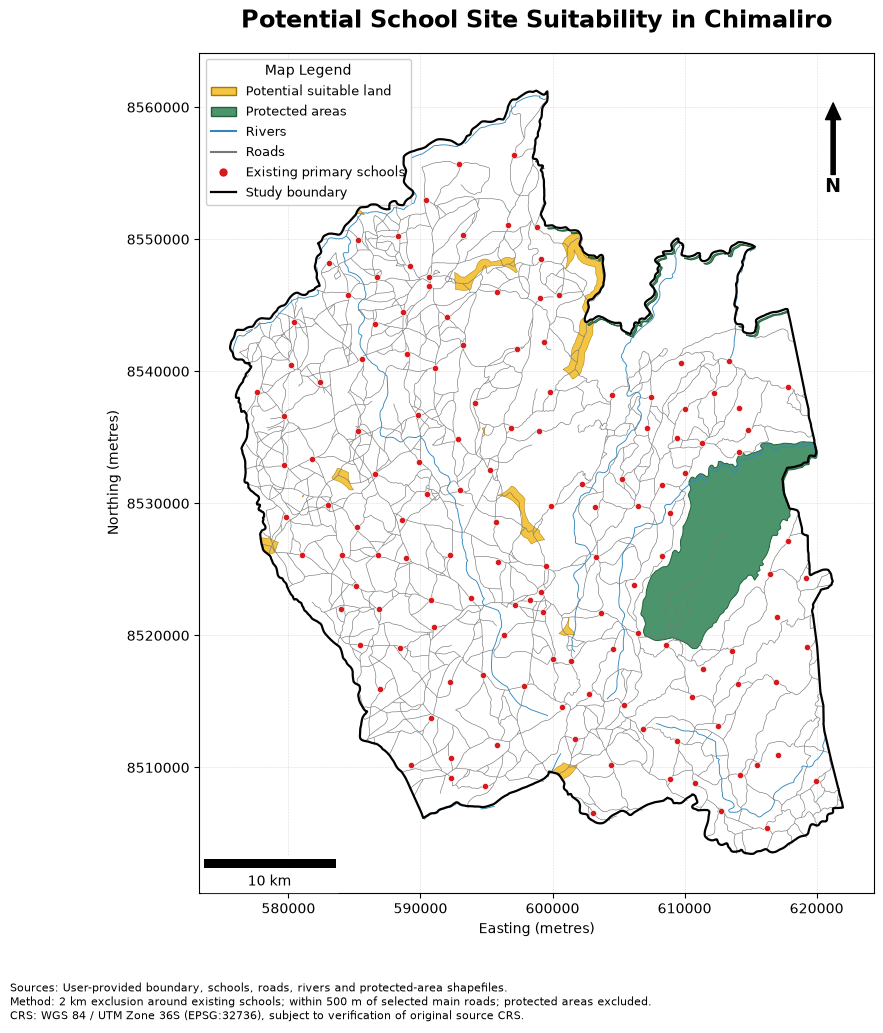

Map saved successfully:
D:\chimaliro-school-site-accessibility\outputs\chimaliro_static_suitability_map.png
D:\chimaliro-school-site-accessibility\outputs\chimaliro_static_suitability_map.pdf


In [25]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# --------------------------------------------------
# 1. Define project paths
# --------------------------------------------------
BASE_DIR = Path(r"D:\chimaliro-school-site-accessibility")

PROCESSED_DIR = BASE_DIR / "data" / "processed_data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Load the processed datasets
# --------------------------------------------------
boundary = gpd.read_file(PROCESSED_DIR / "Boundary_UTM36S.shp")
schools = gpd.read_file(PROCESSED_DIR / "primary_schools_UTM36S.shp")
protected = gpd.read_file(PROCESSED_DIR / "protected_areas_UTM36S.shp")
roads = gpd.read_file(PROCESSED_DIR / "roads_UTM36S.shp")
rivers = gpd.read_file(PROCESSED_DIR / "rivers_UTM36S.shp")

suitability_file = OUTPUT_DIR / "chimaliro_suitability.gpkg"
suitable_land = gpd.read_file(
    suitability_file,
    layer="suitable_land"
)

# --------------------------------------------------
# 3. Check coordinate reference systems
# --------------------------------------------------
layers = {
    "Boundary": boundary,
    "Primary schools": schools,
    "Protected areas": protected,
    "Roads": roads,
    "Rivers": rivers,
    "Suitable land": suitable_land
}

for name, gdf in layers.items():
    print(f"{name}: {len(gdf)} features | CRS: {gdf.crs}")

# Reproject layers to EPSG:32736 if their source CRS
# has already been correctly identified.
TARGET_CRS = "EPSG:32736"

for name, gdf in layers.items():
    if gdf.crs is None:
        raise ValueError(
            f"{name} has no CRS. Identify its true source CRS first."
        )

    if gdf.crs.to_epsg() != 32736:
        layers[name] = gdf.to_crs(TARGET_CRS)

boundary = layers["Boundary"]
schools = layers["Primary schools"]
protected = layers["Protected areas"]
roads = layers["Roads"]
rivers = layers["Rivers"]
suitable_land = layers["Suitable land"]

# --------------------------------------------------
# 4. Create the static map
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 11))

# Suitable land
suitable_land.plot(
    ax=ax,
    color="#F4C542",
    edgecolor="#A87900",
    linewidth=0.35,
    zorder=2
)

# Protected areas
protected.plot(
    ax=ax,
    color="#4C956C",
    edgecolor="#21613A",
    linewidth=0.7,
    zorder=3
)

# Rivers
rivers.plot(
    ax=ax,
    color="#3288BD",
    linewidth=0.65,
    zorder=4
)

# Roads
roads.plot(
    ax=ax,
    color="#777777",
    linewidth=0.45,
    zorder=5
)

# Existing primary schools
schools.plot(
    ax=ax,
    color="#D7191C",
    markersize=20,
    edgecolor="white",
    linewidth=0.45,
    zorder=6
)

# Study boundary
boundary.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.6,
    zorder=7
)

# --------------------------------------------------
# 5. Title and labels
# --------------------------------------------------
ax.set_title(
    "Potential School Site Suitability in Chimaliro",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Easting (metres)", fontsize=10)
ax.set_ylabel("Northing (metres)", fontsize=10)

ax.ticklabel_format(
    style="plain",
    axis="both",
    useOffset=False
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.4,
    alpha=0.45,
    zorder=1
)

ax.set_aspect("equal")

# --------------------------------------------------
# 6. Add a north arrow
# --------------------------------------------------
ax.annotate(
    "N",
    xy=(0.94, 0.94),
    xytext=(0.94, 0.84),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(
        facecolor="black",
        edgecolor="black",
        width=3,
        headwidth=11,
        headlength=12
    ),
    zorder=10
)

# --------------------------------------------------
# 7. Add a scale bar
# --------------------------------------------------
scale_bar = ScaleBar(
    dx=1,
    units="m",
    dimension="si-length",
    location="lower left",
    length_fraction=0.22,
    box_alpha=0.8,
    color="black"
)

ax.add_artist(scale_bar)

# --------------------------------------------------
# 8. Add a custom legend
# --------------------------------------------------
legend_items = [
    Patch(
        facecolor="#F4C542",
        edgecolor="#A87900",
        label="Potential suitable land"
    ),
    Patch(
        facecolor="#4C956C",
        edgecolor="#21613A",
        label="Protected areas"
    ),
    Line2D(
        [0], [0],
        color="#3288BD",
        linewidth=1.5,
        label="Rivers"
    ),
    Line2D(
        [0], [0],
        color="#777777",
        linewidth=1.5,
        label="Roads"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="#D7191C",
        markeredgecolor="white",
        markersize=7,
        label="Existing primary schools"
    ),
    Line2D(
        [0], [0],
        color="black",
        linewidth=1.6,
        label="Study boundary"
    )
]

ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=9,
    frameon=True,
    framealpha=0.95,
    title="Map Legend",
    title_fontsize=10
)

# --------------------------------------------------
# 9. Add source notes
# --------------------------------------------------
source_text = (
    "Sources: User-provided boundary, schools, roads, rivers "
    "and protected-area shapefiles.\n"
    "Method: 2 km exclusion around existing schools; "
    "within 500 m of selected main roads; protected areas excluded.\n"
    "CRS: WGS 84 / UTM Zone 36S (EPSG:32736), subject to "
    "verification of original source CRS."
)

fig.text(
    0.10,
    0.025,
    source_text,
    ha="left",
    va="bottom",
    fontsize=8
)

# Leave room for source notes
fig.tight_layout(rect=[0.03, 0.09, 0.98, 0.96])

# --------------------------------------------------
# 10. Save PNG and PDF
# --------------------------------------------------
png_path = OUTPUT_DIR / "chimaliro_static_suitability_map.png"
pdf_path = OUTPUT_DIR / "chimaliro_static_suitability_map.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Map saved successfully:")
print(png_path)
print(pdf_path)

## 7. Create a self-contained interactive HTML map
The HTML is written to `outputs/interactive_map.html` and can be opened directly in a browser. The basemap requires an internet connection; analytical layers and popups are embedded in the HTML.

In [26]:
%pip install folium geopandas

Note: you may need to restart the kernel to use updated packages.


In [28]:
from pathlib import Path
import geopandas as gpd
import folium
from folium.plugins import Fullscreen, MeasureControl, MiniMap

# Define project directories
BASE_DIR = Path(r"D:\chimaliro-school-site-accessibility")
PROCESSED_DIR = BASE_DIR / "data" / "processed_data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load processed spatial datasets
boundary = gpd.read_file(PROCESSED_DIR / "Boundary_UTM36S.shp")
schools = gpd.read_file(PROCESSED_DIR / "primary_schools_UTM36S.shp")
protected = gpd.read_file(PROCESSED_DIR / "protected_areas_UTM36S.shp")
roads = gpd.read_file(PROCESSED_DIR / "roads_UTM36S.shp")
rivers = gpd.read_file(PROCESSED_DIR / "rivers_UTM36S.shp")

# Load the candidate suitable land generated by the overlay analysis
suitable_land = gpd.read_file(
    OUTPUT_DIR / "chimaliro_suitability.gpkg",
    layer="suitable_land"
)

# Validate CRS metadata before mapping
layers = {
    "Boundary": boundary,
    "Primary schools": schools,
    "Protected areas": protected,
    "Roads": roads,
    "Rivers": rivers,
    "Suitable land": suitable_land
}

for name, gdf in layers.items():
    if gdf.crs is None:
        raise ValueError(
            f"{name} has no CRS. Verify its original CRS before continuing."
        )
    print(f"{name}: {len(gdf)} features | CRS: {gdf.crs}")

# Standardize projected layers for the analytical workflow
# This assumes each source CRS has already been correctly identified
for name, gdf in layers.items():
    if gdf.crs.to_epsg() != 32736:
        layers[name] = gdf.to_crs("EPSG:32736")

boundary = layers["Boundary"]
schools = layers["Primary schools"]
protected = layers["Protected areas"]
roads = layers["Roads"]
rivers = layers["Rivers"]
suitable_land = layers["Suitable land"]

# Convert layers to WGS 84 because Folium requires longitude and latitude
boundary = boundary.to_crs("EPSG:4326")
schools = schools.to_crs("EPSG:4326")
protected = protected.to_crs("EPSG:4326")
roads = roads.to_crs("EPSG:4326")
rivers = rivers.to_crs("EPSG:4326")
suitable_land = suitable_land.to_crs("EPSG:4326")

# Calculate the centre of the study area
centre = boundary.geometry.union_all().centroid

# Create a professional interactive map with a neutral basemap
m = folium.Map(
    location=[centre.y, centre.x],
    zoom_start=12,
    tiles="CartoDB positron",
    control_scale=True,
    prefer_canvas=True
)

# Add a clean boundary outline
folium.GeoJson(
    boundary,
    name="Study boundary",
    style_function=lambda feature: {
        "color": "#172B4D",
        "weight": 3,
        "fillOpacity": 0
    },
    tooltip="Chimaliro study boundary"
).add_to(m)

# Add candidate suitable land
folium.GeoJson(
    suitable_land,
    name="Potential suitable land",
    style_function=lambda feature: {
        "color": "#B8860B",
        "weight": 1,
        "fillColor": "#F2C14E",
        "fillOpacity": 0.72
    },
    tooltip="Potential suitable land"
).add_to(m)

# Add protected areas with available attribute information
protected_fields = [
    col for col in protected.columns if col != "geometry"
][:4]

folium.GeoJson(
    protected,
    name="Protected areas",
    style_function=lambda feature: {
        "color": "#176B45",
        "weight": 1.5,
        "fillColor": "#54A878",
        "fillOpacity": 0.48
    },
    tooltip=folium.GeoJsonTooltip(
        fields=protected_fields,
        aliases=[f"{col.replace('_', ' ').title()}:" for col in protected_fields]
    ) if protected_fields else None,
    popup=folium.GeoJsonPopup(
        fields=protected_fields,
        aliases=[f"{col.replace('_', ' ').title()}:" for col in protected_fields]
    ) if protected_fields else None
).add_to(m)

# Add the road network
folium.GeoJson(
    roads,
    name="Road network",
    style_function=lambda feature: {
        "color": "#707782",
        "weight": 1.2,
        "opacity": 0.85
    },
    tooltip="Road segment"
).add_to(m)

# Add rivers
folium.GeoJson(
    rivers,
    name="Rivers",
    style_function=lambda feature: {
        "color": "#2589BD",
        "weight": 1.6,
        "opacity": 0.9
    },
    tooltip="River"
).add_to(m)

# Add primary schools with popups and visible markers
school_fields = [
    col for col in schools.columns if col != "geometry"
][:5]

folium.GeoJson(
    schools,
    name="Existing primary schools",
    marker=folium.CircleMarker(
        radius=4,
        color="#FFFFFF",
        weight=1.2,
        fill=True,
        fill_color="#C0392B",
        fill_opacity=1
    ),
    tooltip=folium.GeoJsonTooltip(
        fields=school_fields,
        aliases=[f"{col.replace('_', ' ').title()}:" for col in school_fields]
    ) if school_fields else None,
    popup=folium.GeoJsonPopup(
        fields=school_fields,
        aliases=[f"{col.replace('_', ' ').title()}:" for col in school_fields]
    ) if school_fields else None
).add_to(m)

# Add layer selector, fullscreen, distance measurement and minimap
folium.LayerControl(
    position="topright",
    collapsed=False
).add_to(m)

Fullscreen(
    position="topleft",
    title="Enter fullscreen",
    title_cancel="Exit fullscreen"
).add_to(m)

MeasureControl(
    position="topleft",
    primary_length_unit="kilometers",
    secondary_length_unit="meters",
    primary_area_unit="sqkilometers",
    secondary_area_unit="hectares"
).add_to(m)

MiniMap(
    tile_layer="CartoDB positron",
    position="bottomright",
    toggle_display=True,
    width=160,
    height=120
).add_to(m)

# Add a professional map header
header_html = """
<div style="
    position: fixed;
    top: 12px;
    left: 60px;
    z-index: 9999;
    background: rgba(255,255,255,0.97);
    padding: 13px 20px;
    border-left: 5px solid #176B45;
    border-radius: 3px;
    box-shadow: 0 2px 8px rgba(0,0,0,0.18);
    font-family: Arial, sans-serif;
    color: #172B4D;
">
    <div style="font-size: 19px; font-weight: 700;">
        CHIMALIRO SCHOOL SITE SUITABILITY
    </div>
    <div style="font-size: 11px; margin-top: 5px; color: #52606D;">
        SPATIAL ACCESSIBILITY ANALYSIS | MALAWI
    </div>
</div>
"""
m.get_root().html.add_child(folium.Element(header_html))

# Add a compact map legend
legend_html = """
<div style="
    position: fixed;
    bottom: 35px;
    right: 18px;
    z-index: 9999;
    background: rgba(255,255,255,0.97);
    padding: 12px 15px;
    border: 1px solid #D5DADF;
    border-radius: 4px;
    box-shadow: 0 2px 8px rgba(0,0,0,0.15);
    font-family: Arial, sans-serif;
    font-size: 12px;
    color: #263238;
    min-width: 190px;
">
    <div style="font-weight:700; font-size:13px; margin-bottom:9px;">
        MAP LEGEND
    </div>
    <div style="margin:6px 0;">
        <span style="display:inline-block;width:13px;height:13px;
        background:#F2C14E;border:1px solid #B8860B;margin-right:8px;"></span>
        Potential suitable land
    </div>
    <div style="margin:6px 0;">
        <span style="display:inline-block;width:13px;height:13px;
        background:#54A878;border:1px solid #176B45;margin-right:8px;"></span>
        Protected areas
    </div>
    <div style="margin:6px 0;">
        <span style="display:inline-block;width:20px;height:3px;
        background:#707782;margin-right:8px;vertical-align:middle;"></span>
        Roads
    </div>
    <div style="margin:6px 0;">
        <span style="display:inline-block;width:20px;height:3px;
        background:#2589BD;margin-right:8px;vertical-align:middle;"></span>
        Rivers
    </div>
    <div style="margin:6px 0;">
        <span style="display:inline-block;width:10px;height:10px;
        background:#C0392B;border:1px solid white;border-radius:50%;
        margin:0 9px 0 2px;"></span>
        Existing primary schools
    </div>
    <div style="margin:6px 0;">
        <span style="display:inline-block;width:20px;height:3px;
        background:#172B4D;margin-right:8px;vertical-align:middle;"></span>
        Study boundary
    </div>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# Add methodology, CRS and source information
notes_html = """
<div style="
    position: fixed;
    bottom: 12px;
    left: 12px;
    z-index: 9999;
    background: rgba(255,255,255,0.96);
    padding: 9px 12px;
    border: 1px solid #D5DADF;
    border-radius: 3px;
    font-family: Arial, sans-serif;
    font-size: 10px;
    line-height: 1.5;
    color: #374151;
    max-width: 390px;
">
    <b>ANALYTICAL CRITERIA</b><br>
    Within 500 m of selected main roads<br>
    Outside 2 km buffers around existing primary schools<br>
    Protected areas excluded<br>
    <b>Data:</b> User-provided spatial datasets<br>
    <b>Analysis CRS:</b> EPSG:32736, subject to source CRS verification<br>
    <b>Basemap:</b> CARTO Positron, requires internet access
</div>
"""
m.get_root().html.add_child(folium.Element(notes_html))

# Fit the map to the study boundary
minx, miny, maxx, maxy = boundary.total_bounds
m.fit_bounds([[miny, minx], [maxy, maxx]])

# Save the interactive map as an HTML file
html_path = OUTPUT_DIR / "interactive_map.html"
m.save(str(html_path))

print("Professional interactive map created.")
print(f"Output: {html_path}")

Boundary: 1 features | CRS: EPSG:32736
Primary schools: 139 features | CRS: EPSG:32736
Protected areas: 2 features | CRS: EPSG:32736
Roads: 1977 features | CRS: EPSG:32736
Rivers: 51 features | CRS: EPSG:32736
Suitable land: 1 features | CRS: EPSG:32736
Professional interactive map created.
Output: D:\chimaliro-school-site-accessibility\outputs\interactive_map.html


## 8. Export result metadata and discuss limitations
The metadata file records the runtime access timestamp and analysis assumptions. Interpret the result as a first-pass spatial screening, not as a final choice of construction parcels.

In [2]:
# Check the GeoPackage layers without importing fiona
import geopandas as gpd
from pathlib import Path

suitability_path = Path(
    r"D:\chimaliro-school-site-accessibility\outputs\chimaliro_suitability.gpkg"
)

if suitability_path.exists():
    try:
        layers = gpd.list_layers(suitability_path)
        print(layers)
    except (AttributeError, Exception) as exc:
        print("Could not list layers:", exc)
        print("The GeoPackage file exists, but layer listing may require an I/O engine.")
else:
    print("GeoPackage not found:", suitability_path)

                          name geometry_type
0         school_exclusion_2km  MultiPolygon
1        main_road_access_500m  MultiPolygon
2  candidate_before_protection  MultiPolygon
3                suitable_land  MultiPolygon


In [3]:
# Record suitability output details without importing fiona
suitability_path = output_dir / "chimaliro_suitability.gpkg"

suitability_metadata = {
    "file": str(suitability_path),
    "exists": suitability_path.exists()
}

if suitability_path.exists():
    try:
        suitable = gpd.read_file(
            suitability_path,
            layer="suitable_land"
        )

        suitability_metadata["suitable_land_features"] = len(suitable)
        suitability_metadata["crs"] = (
            str(suitable.crs) if suitable.crs else None
        )

    except Exception as exc:
        suitability_metadata["read_error"] = str(exc)

NameError: name 'output_dir' is not defined